## Step 2d: Version 1 vs Version 2

This compares every patient's Dice score from the first training run with the second one, after the brightness and missing-scan fixes.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# style settings
font_size = 20
v1_color = "#9a9a9a"
v2_color = "#5b2a86"
improved_color = "#1d3a8a"
worse_color = "#c44536"
fixed_color = "#2a9d8f"

plt.rcParams["font.size"] = font_size
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#d9d9d9"
plt.rcParams["axes.axisbelow"] = True

os.makedirs("figures", exist_ok=True)
print("Done")

Done


### Load both sets of scores

In [2]:
v1 = pd.read_csv(os.path.join("project3_outputs", "test_dice_scores.csv"))
v2 = pd.read_csv(os.path.join("project3_outputs_v2", "test_dice_scores.csv"))

both = v1[["Patient", "Dice"]].merge(v2[["Patient", "Dice"]], on="Patient", suffixes=(" v1", " v2"))
both["Change"] = both["Dice v2"] - both["Dice v1"]
both.to_csv("dice_v1_vs_v2.csv", index=False)

print(f"{'':32}{'Version 1':>12}{'Version 2':>12}")
print(f"{'Mean Dice':32}{both['Dice v1'].mean():>12.3f}{both['Dice v2'].mean():>12.3f}")
print(f"{'Median Dice':32}{both['Dice v1'].median():>12.3f}{both['Dice v2'].median():>12.3f}")
print(f"{'Patients scoring 0':32}{(both['Dice v1'] == 0).sum():>12}{(both['Dice v2'] == 0).sum():>12}")
print(f"{'Patients scoring 0.7 or higher':32}{(both['Dice v1'] >= 0.7).sum():>12}{(both['Dice v2'] >= 0.7).sum():>12}")

print()
print("Patients that improved by more than 0.05:", (both["Change"] > 0.05).sum())
print("Patients that got worse by more than 0.05:", (both["Change"] < -0.05).sum())
print("Patients within 0.05 either way:", (both["Change"].abs() <= 0.05).sum())

                                   Version 1   Version 2
Mean Dice                              0.682       0.749
Median Dice                            0.799       0.830
Patients scoring 0                        10           2
Patients scoring 0.7 or higher            78          79

Patients that improved by more than 0.05: 38
Patients that got worse by more than 0.05: 22
Patients within 0.05 either way: 50


### Figure 1: Every patient, before and after
Each dot is one patient. The dot's position across shows its version 1 score, and its height shows its version 2 score.

- Dots **above** the diagonal line improved, and dots **below** it got worse.
- The green dots on the far left are the 10 patients that scored 0 in version 1.

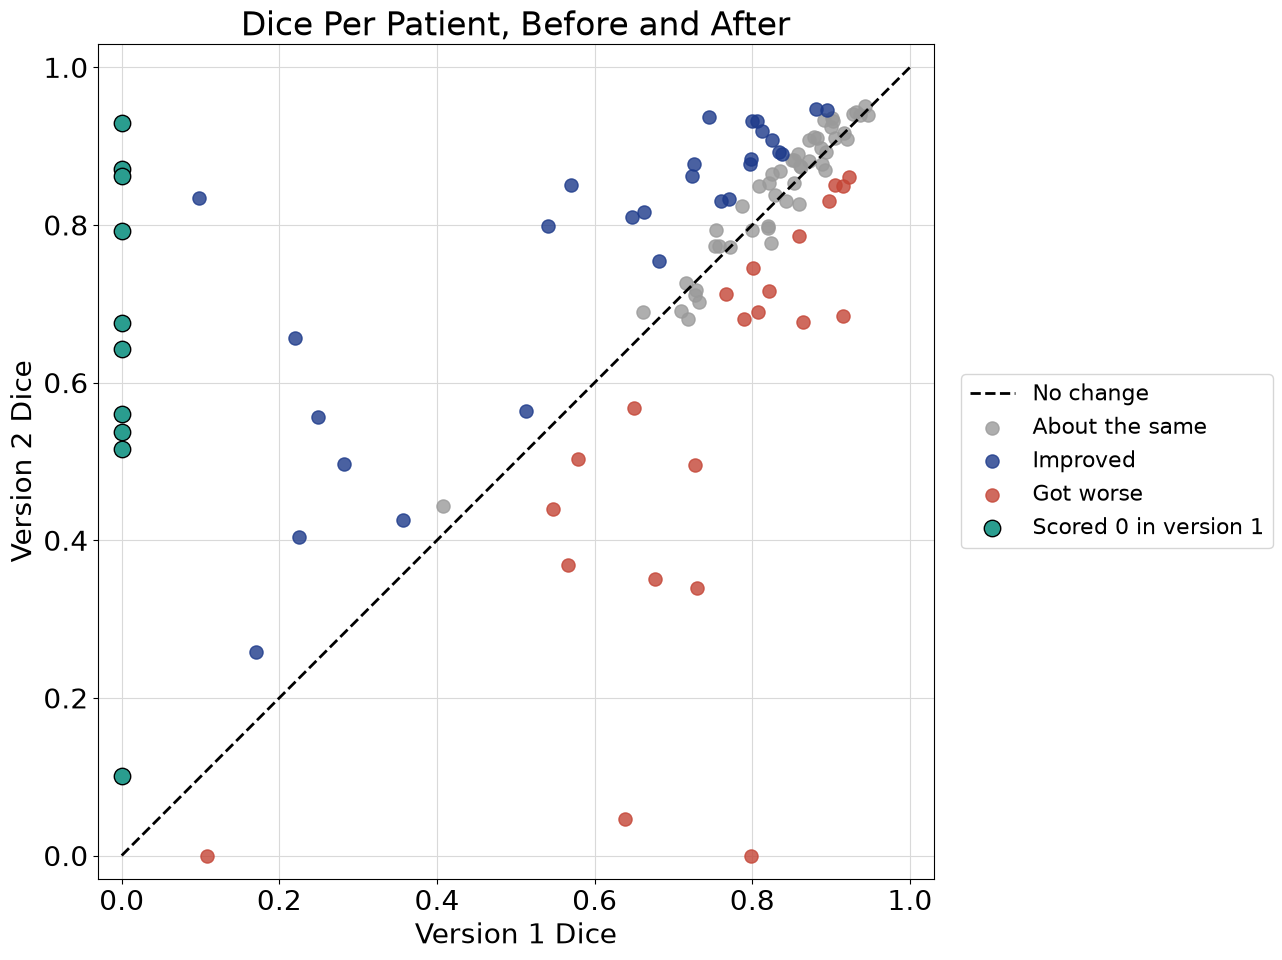

In [3]:
fixed = both["Dice v1"] == 0
improved = (both["Change"] > 0.05) & ~fixed
worse = both["Change"] < -0.05
same = ~fixed & ~improved & ~worse

fig, ax = plt.subplots(figsize=(16, 10))
ax.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=2, label="No change")
ax.scatter(both.loc[same, "Dice v1"], both.loc[same, "Dice v2"], s=90, color=v1_color, alpha=0.8, label="About the same")
ax.scatter(both.loc[improved, "Dice v1"], both.loc[improved, "Dice v2"], s=90, color=improved_color, alpha=0.8, label="Improved")
ax.scatter(both.loc[worse, "Dice v1"], both.loc[worse, "Dice v2"], s=90, color=worse_color, alpha=0.8, label="Got worse")
ax.scatter(both.loc[fixed, "Dice v1"], both.loc[fixed, "Dice v2"], s=140, color=fixed_color, edgecolor="black", label="Scored 0 in version 1")

ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-0.03, 1.03)
ax.set_aspect("equal")
ax.set_xlabel("Version 1 Dice")
ax.set_ylabel("Version 2 Dice")
ax.set_title("Dice Per Patient, Before and After")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=16)   # outside the plot so it never hides a dot
plt.tight_layout()
plt.savefig(os.path.join("figures", "dice_v1_vs_v2_scatter.png"), dpi=200)
plt.show()

### Figure 2: The two score distributions side by side
The same histogram as before, with version 1 in gray and version 2 in purple on top. The bar on the far left (patients scoring near 0) shrinks, and the whole shape shifts to the right.

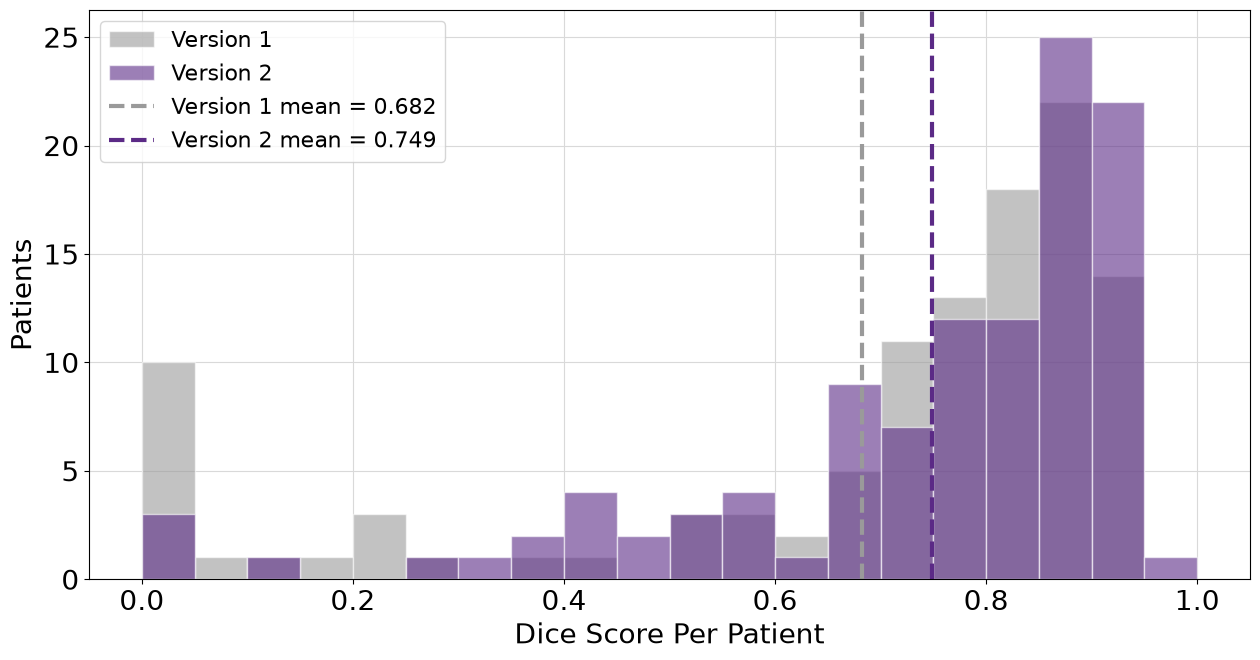

In [4]:
bins = np.linspace(0, 1, 21)

plt.figure(figsize=(13, 7))
plt.hist(both["Dice v1"], bins=bins, color=v1_color, alpha=0.6, edgecolor="white", label="Version 1")
plt.hist(both["Dice v2"], bins=bins, color=v2_color, alpha=0.6, edgecolor="white", label="Version 2")
plt.axvline(both["Dice v1"].mean(), color=v1_color, linestyle="--", linewidth=3,
            label=f"Version 1 mean = {both['Dice v1'].mean():.3f}")
plt.axvline(both["Dice v2"].mean(), color=v2_color, linestyle="--", linewidth=3,
            label=f"Version 2 mean = {both['Dice v2'].mean():.3f}")
plt.xlabel("Dice Score Per Patient")
plt.ylabel("Patients")
plt.legend(loc="upper left", fontsize=16)
plt.tight_layout()
plt.savefig(os.path.join("figures", "dice_v1_vs_v2_histogram.png"), dpi=200)
plt.show()

### What happened to the 10 patients that scored 0
And the biggest gains and losses overall.

In [5]:
print("The 10 patients that scored 0 in version 1:")
print(both[fixed].sort_values("Dice v2", ascending=False).round(3).to_string(index=False))

print()
print("Biggest drops:")
print(both.sort_values("Change").head(5).round(3).to_string(index=False))

The 10 patients that scored 0 in version 1:
     Patient  Dice v1  Dice v2  Change
TCGA_HT_A61A      0.0    0.929   0.929
TCGA_HT_A61B      0.0    0.871   0.871
TCGA_DU_7306      0.0    0.863   0.863
TCGA_HT_A616      0.0    0.792   0.792
TCGA_FG_6688      0.0    0.676   0.676
TCGA_DU_8165      0.0    0.643   0.643
TCGA_CS_5397      0.0    0.560   0.560
TCGA_DU_5852      0.0    0.537   0.537
TCGA_HT_A5RC      0.0    0.515   0.515
TCGA_FG_A60K      0.0    0.101   0.101

Biggest drops:
     Patient  Dice v1  Dice v2  Change
TCGA_FG_8189    0.798    0.000  -0.798
TCGA_CS_6668    0.638    0.047  -0.591
TCGA_CS_6186    0.730    0.340  -0.390
TCGA_DU_A5TP    0.677    0.351  -0.326
TCGA_DU_7294    0.728    0.495  -0.233
